# Neural Networks: An Introduction

A **neural network** is a computational model loosely inspired by biological neurons in the brain. It consists of layers of interconnected nodes called **neurons**, which pass weighted signals to each other to produce an output.

## The Building Block: The Perceptron

The simplest artificial neuron is the **perceptron**. It takes $n$ binary inputs $x_1, x_2, \ldots, x_n \in \{0, 1\}$ and produces a single binary output.

Each input is multiplied by a **weight** $w_i \in \mathbb{R}$, which encodes how important that input is. The neuron computes the **weighted sum**:

$$z = \sum_{i=1}^{n} w_i x_i = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n$$

and fires based on a **threshold** $\theta$:

$$\text{output} = \begin{cases} 0 & \text{if } z \leq \theta \\\ 1 & \text{if } z > \theta \end{cases}$$

It is common to replace $\theta$ with a **bias** $b = -\theta$, giving an equivalent and more convenient form:

$$\text{output} = \begin{cases} 0 & \text{if } \mathbf{w} \cdot \mathbf{x} + b \leq 0 \\\ 1 & \text{if } \mathbf{w} \cdot \mathbf{x} + b > 0 \end{cases}$$

where $\mathbf{w} \cdot \mathbf{x} = \sum_i w_i x_i$ is the dot product of weights and inputs. A large positive bias $b$ makes the neuron fire easily; a very negative $b$ makes it rarely fire.


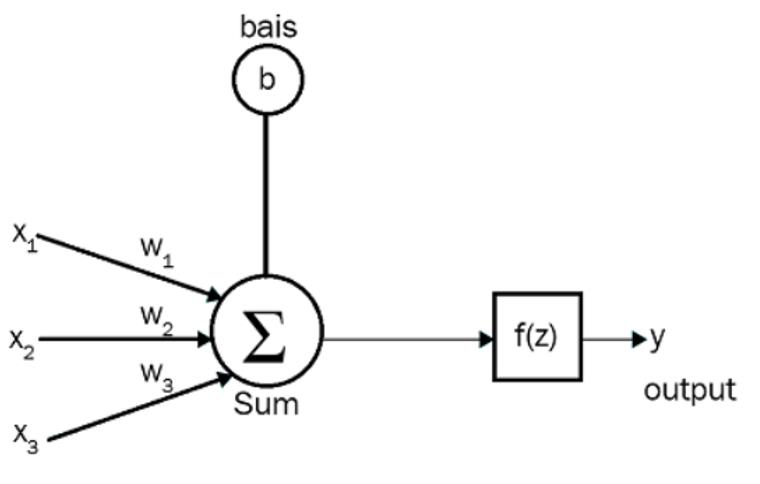

## Example: Should I Go to the Village Fair?
*(Adapted from M. Nielsen, "Neural Networks and Deep Learning")*

You want to decide whether to attend the local fair. Your decision depends on three factors:

| Input | Variable | Meaning |
|:-----:|:--------:|:--------|
| $x_1$ | Weather  | Is the weather good? (1 = yes, 0 = no) |
| $x_2$ | Buses    | Are there buses available? (1 = yes, 0 = no) |
| $x_3$ | Cheese   | Do you like cheese? (1 = a lot, 0 = not much) |

You assign **weights** that reflect how much each factor influences you:

$$w_1 = 6, \quad w_2 = 2, \quad w_3 = 2$$

Weather matters most (weight 6); buses and cheese are secondary (weight 2 each). You set **threshold** $\theta = 5$.

### The Decision Rule

$$\text{go to fair} = \begin{cases} 1 & \text{if } 6x_1 + 2x_2 + 2x_3 > 5 \\\ 0 & \text{otherwise} \end{cases}$$

---

### Numerical Example 1 — Sunny day, buses running, cheese lover

$$x_1 = 1, \quad x_2 = 1, \quad x_3 = 1$$

$$z = 6 \cdot 1 + 2 \cdot 1 + 2 \cdot 1 = 6 + 2 + 2 = 10$$

Since $z = 10 > 5 = \theta$ &nbsp;$\Longrightarrow$&nbsp; **output = 1** $\rightarrow$ Go to the fair!

---

### Numerical Example 2 — Rainy day, buses running, cheese lover

$$x_1 = 0, \quad x_2 = 1, \quad x_3 = 1$$

$$z = 6 \cdot 0 + 2 \cdot 1 + 2 \cdot 1 = 0 + 2 + 2 = 4$$

Since $z = 4 \leq 5 = \theta$ &nbsp;$\Longrightarrow$&nbsp; **output = 0** $\rightarrow$ Stay home.

> **Key insight:** Because $w_1 = 6 > \theta = 5$, good weather alone is enough to go. Bad weather contributes 0, leaving only $w_2 + w_3 = 4 < 5$ — rain keeps you home regardless of buses or cheese. By tuning weights and threshold we encode our priorities.


# Building Neural Network from Scratch

## AND Function with a Perceptron

The **AND** function takes two binary inputs and returns 1 only when **both** inputs are 1. Its truth table is:

| $x_1$ | $x_2$ | $x_1 \text{ AND } x_2$ |
|:-----:|:-----:|:----------------------:|
|   0   |   0   |           0            |
|   0   |   1   |           0            |
|   1   |   0   |           0            |
|   1   |   1   |           1            |

### Implementing AND with a Perceptron

Choose weights $w_1 = w_2 = 1$ and threshold $\theta = 1.5$ (equivalently, bias $b = -1.5$):

$$z = 1 \cdot x_1 + 1 \cdot x_2, \qquad \text{output} = \begin{cases} 1 & \text{if } z > 1.5 \\ 0 & \text{otherwise} \end{cases}$$

Verification:

| $x_1$ | $x_2$ | $z = x_1 + x_2$ | $z > 1.5$? | output |
|:-----:|:-----:|:---------------:|:----------:|:------:|
|   0   |   0   |       $0$       |     No     |   0    |
|   0   |   1   |       $1$       |     No     |   0    |
|   1   |   0   |       $1$       |     No     |   0    |
|   1   |   1   |       $2$       |   **Yes**  | **1**  |

The threshold $\theta = 1.5$ sits strictly between 1 (the maximum sum when only one input is active) and 2 (both active), so the perceptron fires **if and only if** both inputs are 1.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([ [0, 1], [1, 0], [1, 1],[0, 0] ])
y = np.array([ [0], [0], [1], [0]])

In [ ]:
assert x.shape == (4, 2), f"x shape mismatch: {x.shape}"
assert y.shape == (4, 1), f"y shape mismatch: {y.shape}"

Initialize weights and bias randomly. Since AND is linearly separable, a **single neuron** is enough — no hidden layer needed. `w` has shape `(2, 1)`: one weight per input feature.

In [ ]:
w = np.random.randn(2, 1)   # shape (2, 1): one weight per input
b = np.zeros((1, 1))        # single bias term

In [ ]:
assert w.shape == (2, 1), f"w shape mismatch: {w.shape}"
assert b.shape == (1, 1), f"b shape mismatch: {b.shape}"

Define the forward propagation. With a single neuron there is only one layer:

$$z = x \cdot w + b \qquad \hat{y} = z$$

In [ ]:
def forward_prop(x, w, b):
    z     = np.dot(x, w) + b   # linear combination: (4,2)·(2,1) → (4,1)
    y_hat = z
    return y_hat

Define the backward propagation. With a single neuron the chain rule gives directly:

$$\frac{\partial J}{\partial w} = x^T \cdot \delta \qquad \frac{\partial J}{\partial b} = \sum \delta$$

where $\delta = -(y - \hat{y})$ is the error signal at the output.

In [ ]:
def backward_prop(x, y, y_hat):
    delta  = -(y - y_hat)                           # error signal: (4,1)
    dJ_dw  = np.dot(x.T, delta)                     # gradient w.r.t. weights: (2,1)
    dJ_db  = np.sum(delta, axis=0, keepdims=True)   # gradient w.r.t. bias: (1,1)
    return dJ_dw, dJ_db

Define the cost function — mean squared error:

$$J = \frac{1}{2} \sum (y - \hat{y})^2$$

In [ ]:
def cost_function(y, y_hat):
    return 0.5 * np.sum((y - y_hat) ** 2)

Set learning rate and number of training iterations:

In [ ]:
alpha          = 0.1
num_iterations = 10_000

Train the single neuron — at each iteration: forward pass → compute gradients → update weights:

In [ ]:
def train(x, y, w, b, alpha, num_iterations):
    cost_history = []

    for i in range(num_iterations):
        # Forward pass: compute prediction
        y_hat = forward_prop(x, w, b)

        # Backward pass: compute gradients
        dJ_dw, dJ_db = backward_prop(x, y, y_hat)

        # Update weights and bias (gradient descent)
        w = w - alpha * dJ_dw
        b = b - alpha * dJ_db

        # Record cost
        cost_history.append(cost_function(y, y_hat))

    return cost_history, y_hat

cost_history, y_hat = train(x, y, w, b, alpha, num_iterations)

print("Final predictions:")
print(np.round(y_hat, 3))

Final predictions:
[[ 0.25]
 [ 0.25]
 [ 0.75]
 [-0.25]]


Plot the cost over training iterations:

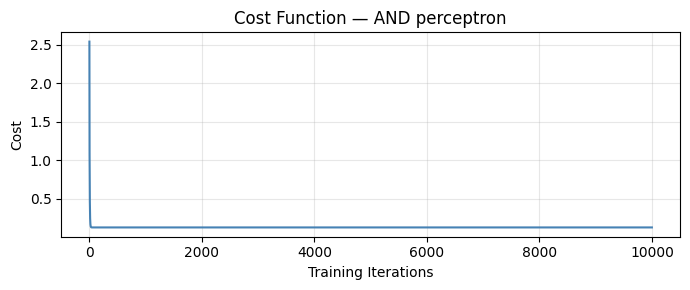

In [ ]:
plt.figure(figsize=(7, 3))
plt.plot(range(num_iterations), cost_history, color='steelblue')
plt.title('Cost Function — AND perceptron')
plt.xlabel('Training Iterations')
plt.ylabel('Cost')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## From a Single Neuron to a Network

A single perceptron can only compute **linearly separable** functions. To solve more complex problems, we stack neurons into **layers**:



For a network with $L$ layers, the output of layer $l$ is computed via **forward propagation**:

$$\mathbf{a}^{(l)} = \sigma\!\left(W^{(l)}\, \mathbf{a}^{(l-1)} + \mathbf{b}^{(l)}\right)$$

where:
- $W^{(l)}$ — **weight matrix** for layer $l$
- $\mathbf{b}^{(l)}$ — **bias vector** for layer $l$
- $\mathbf{a}^{(l-1)}$ — activations from the previous layer, with $\mathbf{a}^{(0)} = \mathbf{x}$
- $\sigma(\cdot)$ — a non-linear **activation function** applied element-wise

The network **learns** by adjusting $W^{(l)}$ and $\mathbf{b}^{(l)}$ to minimise a **loss function** $\mathcal{L}(\hat{y}, y)$ via **gradient descent**:

$$W^{(l)} \leftarrow W^{(l)} - \eta \frac{\partial \mathcal{L}}{\partial W^{(l)}}$$

where $\eta > 0$ is the **learning rate**. Gradients are propagated backwards using the chain rule (**backpropagation**). Through many iterations over training data, the network learns a mapping from inputs to outputs without explicit rules.

Disadvantage of single perceptron is that it only output binary values and if we try to give small change in weight and bais then perceptron can flip the output. We need some system which can modify the output slightly according to small change in weight and bias. Here comes sigmoid function in picture.

If we change perceptron with a sigmoid/tanh function, then we can make slight change in output. But the number of activation functions are large. Nowadays, RELU is the most used activation function.

## Exploring activation functions


An activation function, also known as a transfer function, plays a vital role in neural
networks. It is used to introduce non-linearity in neural networks. As we learned before, we
apply the activation function to the input, which is multiplied by weights and added to the
bias, that is, $f(z)$ , where z = (input * weights) + bias and $f(\cdot)$ is the activation function. If we do
not apply the activation function, then a neuron simply resembles the linear regression. Also with more neurons, remains linear (not sufficient for complex problems). The
aim of the activation function is to introduce a non-linear transformation to learn the
complex underlying patterns in the data.


### Overview

Activation functions introduce **non-linearity** into neural networks — without them, stacking layers would collapse into a single linear transformation and the network could not learn complex patterns.

Below we explore the most important activation functions. A few notable ones beyond the list above:
- **Softplus** $\log(1+e^z)$: smooth ReLU approximation
- **SELU** (Scaled ELU): self-normalizing, preserves mean/variance through layers
- **Mish** $z\cdot\tanh(\text{softplus}(z))$: smooth, non-monotonic, used in YOLOv4

| Function | Formula | Output range | Zero-centered | Vanishing gradient |
|:---------|:--------|:------------:|:-------------:|:------------------:|
| Sigmoid  | $\frac{1}{1+e^{-z}}$ | $(0,1)$ | No | Yes |
| Tanh     | $\frac{e^z-e^{-z}}{e^z+e^{-z}}$ | $(-1,1)$ | Yes | Yes |
| ReLU     | $\max(0,z)$ | $[0,+\infty)$ | No | No (for $z>0$) |
| Leaky ReLU | $\max(\alpha z,z)$, $\alpha{=}0.01$ | $(-\infty,+\infty)$ | No | No |
| ELU      | $z$ if $z{>}0$, else $\alpha(e^z{-}1)$ | $(-\alpha,+\infty)$ | ~Yes | No |
| GELU     | $z\,\Phi(z)$ | $(-\infty,+\infty)$ | ~Yes | No |
| Swish    | $z\cdot\sigma(z)$ | $(-\infty,+\infty)$ | ~Yes | No |
| Softmax  | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0,1)$, sums to 1 | No | — |

### Sigmoid  $\sigma(z) = \dfrac{1}{1+e^{-z}}$

**Pros:** smooth and differentiable everywhere; output interpretable as a probability $(0,1)$.  
**Cons:** vanishing gradients for large $|z|$ (saturates near 0 and 1); output not zero-centered (slows learning); slower than ReLU.

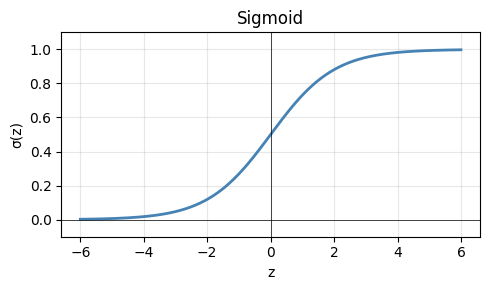

In [ ]:
z = np.linspace(-6, 6, 400)

def sigmoid(z):
    return 1 / (1+np.exp(-z))

y = sigmoid(z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='steelblue', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.ylim(-0.1, 1.1); plt.title('Sigmoid'); plt.xlabel('z'); plt.ylabel('σ(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### $\tanh(z) = \dfrac{e^z - e^{-z}}{e^z + e^{-z}}$

**Pros:** zero-centered output $(-1,1)$, stronger gradients than sigmoid near 0.  
**Cons:** still saturates for large $|z|$ (vanishing gradient); more expensive than ReLU.

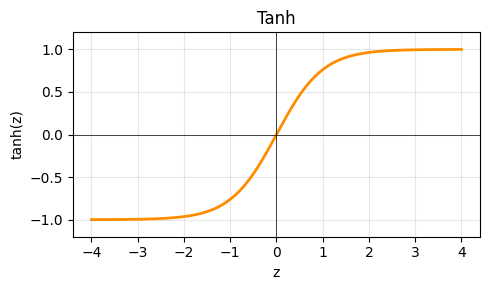

In [ ]:
z = np.linspace(-4, 4, 400)
y = np.tanh(z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='darkorange', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.ylim(-1.2, 1.2); plt.title('Tanh'); plt.xlabel('z'); plt.ylabel('tanh(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### ReLU  $\text{ReLU}(z) = \max(0, z)$

**Pros:** no vanishing gradient for $z>0$; computationally cheap; promotes sparse activations.  
**Cons:** *dying ReLU* — neurons with $z<0$ always output 0 and stop learning; output not zero-centered.

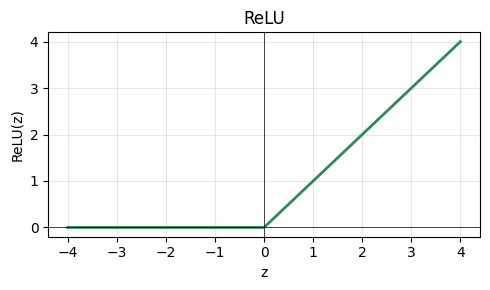

In [ ]:
z = np.linspace(-4, 4, 400)
y = np.maximum(0, z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='seagreen', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title('ReLU'); plt.xlabel('z'); plt.ylabel('ReLU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Leaky ReLU  $\text{LeakyReLU}(z) = \max(\alpha z,\, z)$, with $\alpha = 0.01$

**Pros:** fixes the dying ReLU problem — negative inputs still produce a small gradient $\alpha$.  
**Cons:** $\alpha$ is a hyperparameter to tune; not always better than ReLU in practice.

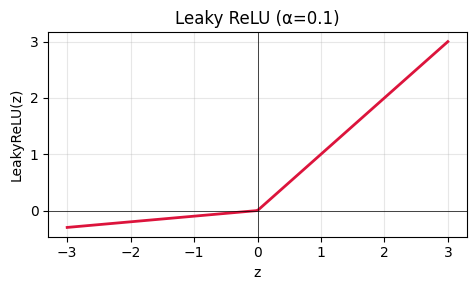

In [ ]:
alpha = 0.1
z = np.linspace(-3, 3, 200)
y = np.where(z > 0, z, alpha * z)

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='crimson', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title(f'Leaky ReLU (α={alpha})'); plt.xlabel('z'); plt.ylabel('LeakyReLU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### ELU  $\text{ELU}(z) = \begin{cases} z & z > 0 \\ \alpha(e^z - 1) & z \leq 0 \end{cases}$

**Pros:** smooth everywhere (including at $z=0$); negative saturation pushes mean activation towards 0; faster convergence than ReLU.  
**Cons:** slightly more expensive to compute (exponential); $\alpha$ is a hyperparameter.

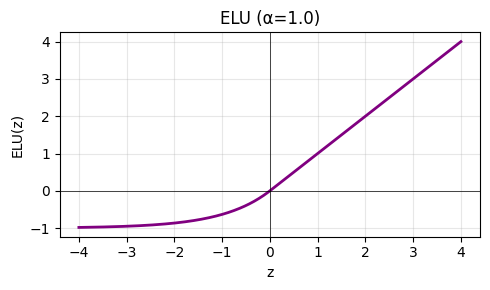

In [ ]:
alpha = 1.0
z = np.linspace(-4, 4, 400)
y = np.where(z > 0, z, alpha * (np.exp(z) - 1))

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='purple', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title(f'ELU (α={alpha})'); plt.xlabel('z'); plt.ylabel('ELU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### GELU  $\text{GELU}(z) = z\,\Phi(z)$

where $\Phi(z)$ is the standard normal CDF. In practice approximated as:

$$\text{GELU}(z) \approx 0.5z\left(1 + \tanh\!\left[\sqrt{\tfrac{2}{\pi}}\left(z + 0.044715\,z^3\right)\right]\right)$$

**Pros:** smooth, non-monotonic; stochastic regularization effect; default in BERT, GPT, and most modern Transformers.  
**Cons:** more expensive than ReLU; less intuitive than simpler functions.

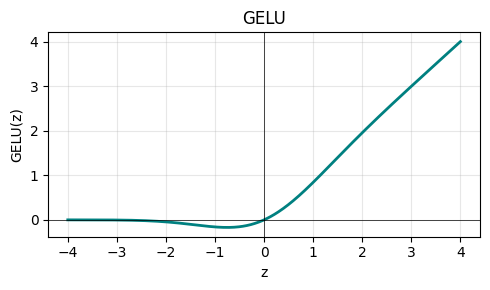

In [ ]:
z = np.linspace(-4, 4, 400)
y = 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3)))

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='teal', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title('GELU'); plt.xlabel('z'); plt.ylabel('GELU(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Swish  $\text{Swish}(z) = z \cdot \sigma(z) = \dfrac{z}{1+e^{-z}}$

**Pros:** smooth, non-monotonic, self-gated; empirically outperforms ReLU on deep networks; no hyperparameters.  
**Cons:** slightly more expensive than ReLU; small dip below zero can be unexpected.

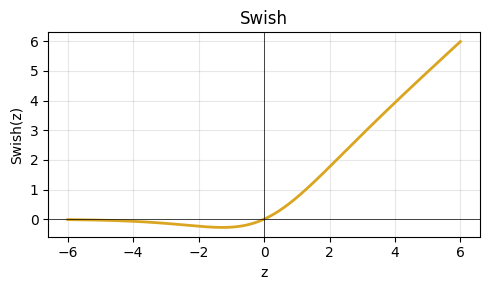

In [ ]:
z = np.linspace(-6, 6, 400)
y = z / (1 + np.exp(-z))

plt.figure(figsize=(5, 3))
plt.plot(z, y, color='goldenrod', linewidth=2)
plt.axhline(0, color='k', linewidth=0.5); plt.axvline(0, color='k', linewidth=0.5)
plt.title('Swish'); plt.xlabel('z'); plt.ylabel('Swish(z)')
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

### Softmax  $\text{Softmax}(z_i) = \dfrac{e^{z_i}}{\displaystyle\sum_{j=1}^{K} e^{z_j}}$

**Pros:** outputs form a valid probability distribution (all positive, sum to 1); ideal for multi-class classification output layer; pairs naturally with cross-entropy loss.  
**Cons:** used **only in the output layer**, not hidden layers; expensive for very large $K$ (e.g. large vocabularies); sensitive to large logit differences (can saturate).

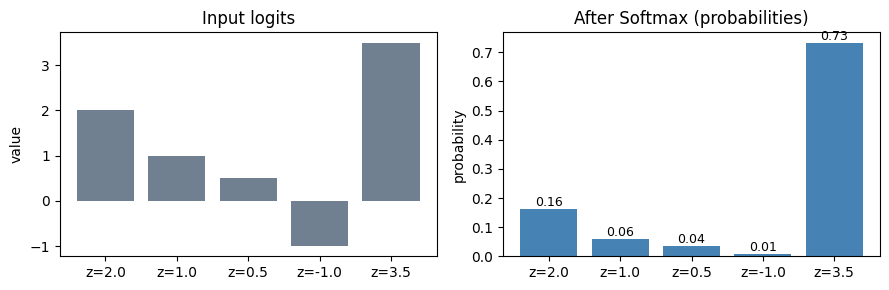

Sum of probabilities: 1.0000


In [ ]:
logits = np.array([2.0, 1.0, 0.5, -1.0, 3.5])
probs  = np.exp(logits) / np.exp(logits).sum()
labels = [f'z={v}' for v in logits]

fig, axes = plt.subplots(1, 2, figsize=(9, 3))

axes[0].bar(labels, logits, color='slategray')
axes[0].set_title('Input logits'); axes[0].set_ylabel('value')

axes[1].bar(labels, probs, color='steelblue')
axes[1].set_title('After Softmax (probabilities)')
axes[1].set_ylabel('probability')
for i, p in enumerate(probs):
    axes[1].text(i, p + 0.01, f'{p:.2f}', ha='center', fontsize=9)

plt.tight_layout(); plt.show()
print(f'Sum of probabilities: {probs.sum():.4f}')

# The main steps for building a Neural Network

- Create (or obtain, if already exists) and preprocess the dataset
- Define the model structure (such as number of input features and outputs)
- Initialize the model's parameters.
- Loop:
   - Calculate current loss (forward propagation)
   - Calculate current gradient (backward propagation)
   - Update parameters (gradient descent)

Tuning the learning rate (which is an example of a "hyperparameter") can make a big difference to the algorithm.

# Implement XOR network

To perform the XOR gate operation, we build a simple two-layer neural network as shown
in the following figure. As you can observe, we have an input layer with two nodes, a
hidden layer with five nodes and an output layers which consist of 1 node:

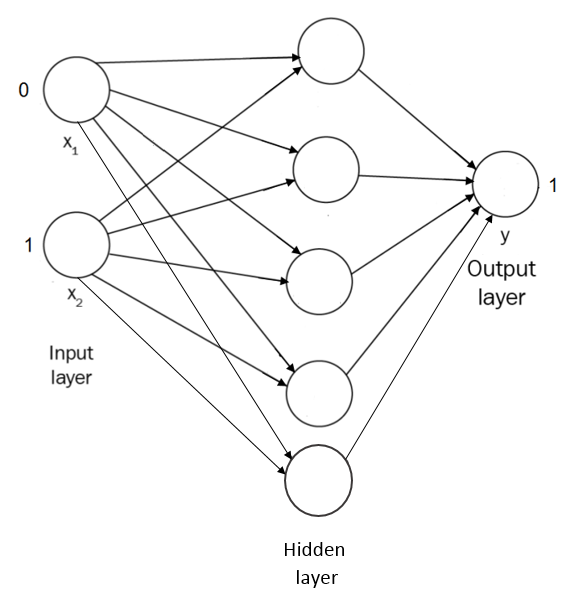

---

### Input: 2 neurons

$x = [x_1, x_2]^T \in \mathbb{R}^{2 \times 1}$

---

### Hidden layer: 5 neurons

Notation -> superscript = layer, subscript = neuron index / connection.

For $j = 1, \dots, 5$:

$$
z^{(1)}_j = w^{(1)}_{j1} x_1 + w^{(1)}_{j2} x_2 + b^{(1)}_j
$$

$$
a^{(1)}_j = \sigma\left(z^{(1)}_j\right)
$$

Expands it in:

$$
z^{(1)}_1 = w^{(1)}_{11} x_1 + w^{(1)}_{12} x_2 + b^{(1)}_1, \quad a^{(1)}_1 = \sigma(z^{(1)}_1)
$$

$$
z^{(1)}_2 = w^{(1)}_{21} x_1 + w^{(1)}_{22} x_2 + b^{(1)}_2, \quad a^{(1)}_2 = \sigma(z^{(1)}_2)
$$

$$
z^{(1)}_3 = w^{(1)}_{31} x_1 + w^{(1)}_{32} x_2 + b^{(1)}_3, \quad a^{(1)}_3 = \sigma(z^{(1)}_3)
$$

$$
z^{(1)}_4 = w^{(1)}_{41} x_1 + w^{(1)}_{42} x_2 + b^{(1)}_4, \quad a^{(1)}_4 = \sigma(z^{(1)}_4)
$$

$$
z^{(1)}_5 = w^{(1)}_{51} x_1 + w^{(1)}_{52} x_2 + b^{(1)}_5, \quad a^{(1)}_5 = \sigma(z^{(1)}_5)
$$

---

### Output layer: 1 neurons

$$
z^{(2)} = w^{(2)}_{1} a^{(1)}_1 + w^{(2)}_{2} a^{(1)}_2 + w^{(2)}_{3} a^{(1)}_3 + w^{(2)}_{4} a^{(1)}_4 + w^{(2)}_{5} a^{(1)}_5 + b^{(2)}
$$

$$
y = \sigma\left(z^{(2)}\right)
$$


### Matrix form

#### First layer

$$
W^{(1)} \in \mathbb{R}^{5 \times 2} =
\begin{bmatrix}
w^{(1)}_{11} & w^{(1)}_{12} \\
w^{(1)}_{21} & w^{(1)}_{22} \\
w^{(1)}_{31} & w^{(1)}_{32} \\
w^{(1)}_{41} & w^{(1)}_{42} \\
w^{(1)}_{51} & w^{(1)}_{52}
\end{bmatrix}
$$

$$
b^{(1)} \in \mathbb{R}^{5 \times 1} =
\begin{bmatrix}
b^{(1)}_1 \\
b^{(1)}_2 \\
b^{(1)}_3 \\
b^{(1)}_4 \\
b^{(1)}_5
\end{bmatrix}
$$

$$
z^{(1)} = W^{(1)} x + b^{(1)}
$$

$$
a^{(1)} = \sigma\left(z^{(1)}\right)
$$

---

### Second layer

$$
W^{(2)} \in \mathbb{R}^{1 \times 5} =
\begin{bmatrix}
w^{(2)}_{1} & w^{(2)}_{2} & w^{(2)}_{3} & w^{(2)}_{4} & w^{(2)}_{5}
\end{bmatrix}
$$

$$
b^{(2)} \in \mathbb{R}
$$

$$
z^{(2)} = W^{(2)} a^{(1)} + b^{(2)}
$$

$$
y = \sigma\left(z^{(2)}\right)
$$

---

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([ [0, 1], [1, 0], [1, 1],[0, 0] ])
y = np.array([ [1], [1], [0], [0]])

In [ ]:
assert x.shape == (4, 2), f"x shape mismatch: {x.shape}"
assert y.shape == (4, 1), f"y shape mismatch: {y.shape}"

Define the number of nodes in each layers

In [ ]:
num_input = 2
num_hidden = 5
num_output = 1

Initialize weights and bias randomly. `Wxh` connects the **input layer** to the **hidden layer** — names follow the convention $W_{\text{source} \to \text{dest}}$:

- Shape: $(2 \times 5)$ — 2 input nodes, 5 hidden nodes
- Each value encodes how much influence each input has on each hidden node

In [ ]:
Wxh = np.random.randn(num_input, num_hidden)
bh  = np.zeros((1, num_hidden))

In [ ]:
assert Wxh.shape == (num_input, num_hidden), f"Wxh shape mismatch: {Wxh.shape}"
assert bh.shape == (1, num_hidden), f"bh shape mismatch: {bh.shape}"

Initialize hidden-to-output weights. `Why` connects the **hidden layer** to the **output layer**:

- Shape: $(5 \times 1)$ — 5 hidden nodes, 1 output node
- Each value encodes how much influence each hidden node has on the output

In [ ]:
Why = np.random.randn(num_hidden, num_output)
by  = np.zeros((1, num_output))

In [ ]:
assert Why.shape == (num_hidden, num_output), f"Why shape mismatch: {Why.shape}"
assert by.shape == (1, num_output), f"by shape mismatch: {by.shape}"

Define the forward propagation

$$
a^{(1)} = \sigma\left(W^{(1)} x + b^{(1)}\right)
$$

$$
y = \sigma\left(W^{(2)} a^{(1)} + b^{(2)}\right)
$$

In [ ]:
def forward_prop(x,Wxh,Why):
    z1 = np.dot(x,Wxh) + bh
    a1 = sigmoid(z1)
    z2 = np.dot(a1,Why) + by
    y_hat = sigmoid(z2)
    
    return z1,a1,z2,y_hat

Define the sigmoid derivative

In [ ]:
def sigmoid_derivative(z):
    return np.exp(-z) / ((1 + np.exp(-z)) ** 2)

Define the backward propagation. The forward pass is:

$$x \xrightarrow{W_{xh}} z_1 = x \cdot W_{xh} + b_h \xrightarrow{\sigma} a_1 \xrightarrow{W_{hy}} z_2 = a_1 \cdot W_{hy} + b_y \xrightarrow{\sigma} \hat{y}$$

with cost $J = \frac{1}{2}(y - \hat{y})^2$.

**Output layer gradient** — applying the chain rule to $\frac{\partial J}{\partial W_{hy}}$:

$$\delta_2 = -(y - \hat{y}) \cdot \sigma'(z_2) \qquad \frac{\partial J}{\partial W_{hy}} = a_1^T \cdot \delta_2$$

**Hidden layer gradient** — the error propagates back through $W_{hy}$:

$$\delta_1 = (\delta_2 \cdot W_{hy}^T) \cdot \sigma'(z_1) \qquad \frac{\partial J}{\partial W_{xh}} = x^T \cdot \delta_1$$

In [ ]:
def backword_prop(y_hat, z1, a1, z2):
    delta2   = np.multiply(-(y - y_hat), sigmoid_derivative(z2))
    dJ_dWhy  = np.dot(a1.T, delta2)
    delta1   = np.dot(delta2, Why.T) * sigmoid_derivative(z1)
    dJ_dWxh  = np.dot(x.T, delta1)
    return dJ_dWxh, dJ_dWhy

## NumPy Best Practices for Neural Networks

From https://github.com/amanchadha/coursera-deep-learning-specialization/

When implementing neural networks with NumPy, always follow these four guidelines:

1. **Avoid rank-1 arrays** — never use shapes like `(m,)`; they behave unexpectedly with dot products and transposes.
2. **Use explicit 2D shapes** — prefer `(m, 1)` column vectors over flat arrays; use `reshape(m, 1)` when needed.
3. **Assert shapes** — add `assert` statements after every variable definition to catch shape bugs early.
4. **Avoid rank-1 matrices** — always initialize weights and biases with explicit 2D shapes, e.g. `np.random.randn(n, 1)` instead of `np.random.randn(n)`.

Start training of the network

In [ ]:
def train_nn(x, y, Wxh, Why, num_iterations, alpha):
    cost_history = []
    for i in range(num_iterations):
        
        #perform forward propagation and predict output
        z1,a1,z2,y_hat = forward_prop(x,Wxh,Why)
        
        #perform backward propagation and calculate gradients
        dJ_dWxh, dJ_dWhy = backword_prop(y_hat, z1, a1, z2)
            
        #update the weights
        Wxh = Wxh -alpha * dJ_dWxh
        Why = Why -alpha * dJ_dWhy
        
        #compute cost
        c = cost_function(y, y_hat)
        
        #store the cost
        cost_history.append(c)

        if i % 1000 == 0:
            print(f"Cost after iteration {i}: {c}")

    return cost_history, y_hat

cost_history, y_hat = train_nn(x, y, Wxh, Why, num_iterations, alpha)

Cost after iteration 0: 0.50786104986611
Cost after iteration 1000: 0.04968173345562462
Cost after iteration 2000: 0.014621903470774921
Cost after iteration 3000: 0.008008550723291121
Cost after iteration 4000: 0.005410505922691619
Cost after iteration 5000: 0.004051549752629084
Cost after iteration 6000: 0.0032238330214535227
Cost after iteration 7000: 0.002669694468549878
Cost after iteration 8000: 0.002274025641752882
Cost after iteration 9000: 0.001978001333770774


Now see the final predictions, so the vector of the weights that we are learned from the training.

In [ ]:
print("Final predictions:")
print(y_hat)

Final predictions:
[[0.97492245]
 [0.96970537]
 [0.02516823]
 [0.03629618]]


Plot cost function

Text(0, 0.5, 'Cost')

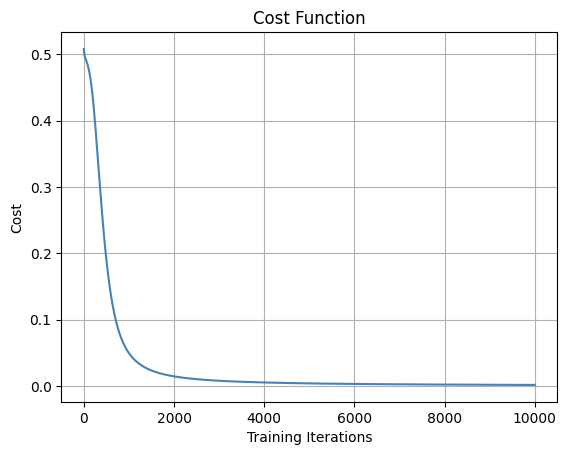

In [ ]:
plt.grid()
plt.plot(range(num_iterations),cost_history, color='steelblue')

plt.title('Cost Function')
plt.xlabel('Training Iterations')
plt.ylabel('Cost')

---

# Single neuron == linear regression without applying activation(perceptron)

---

# Demystigying gradient descent

Before going ahead, first, let us understand the basics. What is a function in mathematics?
A function represents the relation between input and output. We generally use $f$ to
denote the function. For instance, $f(x) = x^2$ implies a function which takes as $x$ an
input and returns $x^2$ as an output. It can also be represented as $ y = x^2$.
So, we have a function $ y = x^2$ , we can plot and see what our function looks like:

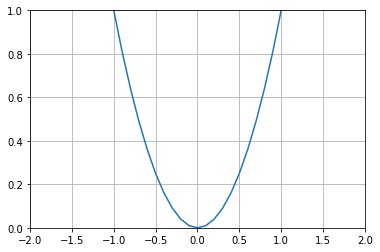


A minimum of the function is called the smallest value of a function. Like as you can see in
the above figure, a minimum of the  $x^2$ function lies at 0. The above function is called a
convex function where we have only one minimum value. A function is called
a nonconvex function where there is more than one minimum value. As shown in the
following figure, a nonconvex function can have many local minima and one global
minimum value whereas a convex function has only one global minimum value. 

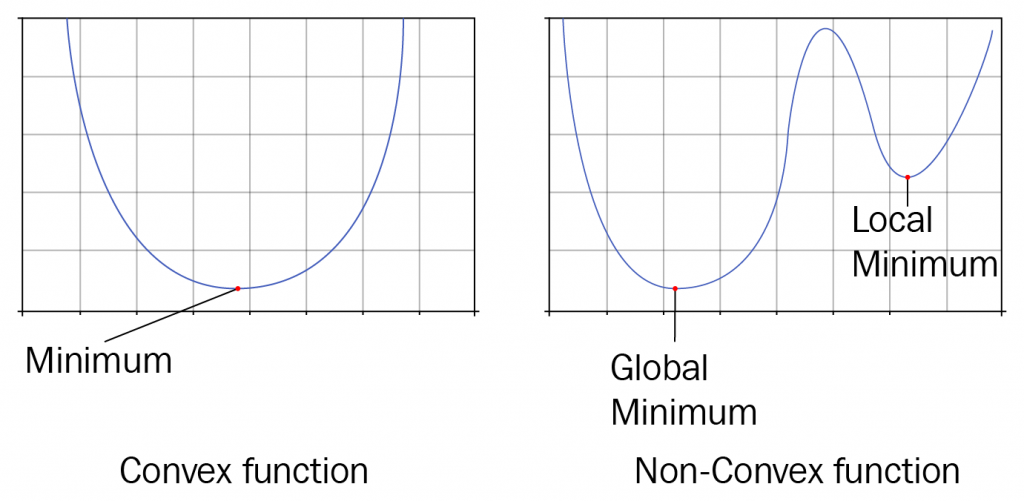

By looking at the graph of $x^2$ function we easily said that it has its minimum value at $x=0$. But how can we find the minimum value of a function mathematically? First, let us assume, x=0.7 Thus, we are at a position where x = 0.7 as shown in the following graph. 

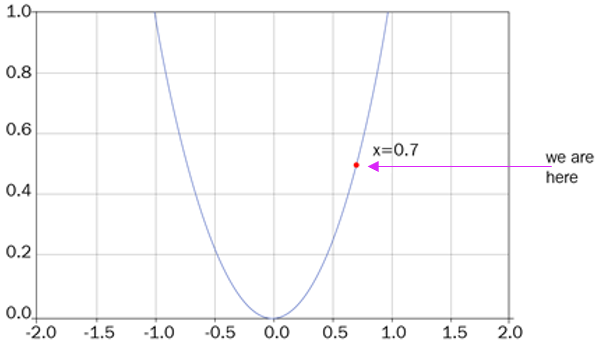

Now we need to go to zero, which is our minimum value, but how can reach there? We can
reach there by calculating the derivative of the function $y=x^2$. So derivative of the
function $y$ with respect to $x$ is given as,

$$y = x^2$$

$$ \frac{d y}{d x}=2 x $$

As we are at x=0.7, substituting this in the above equation, we get,

$$\frac{d y}{d x}=2(0.7)=1.4$$


After calculating the derivative, we update our position of $x$ by the following update rule:

$$x=x-\frac{d y}{d x}$$


$$x=0.7-1.4$$

$$ x=-0.7$$


As shown in the below figure, first we were at x=0.7 but after computing gradient, we are
now at the updated position x =-0.7. But this is something we don't want. Because we
missed our minimum value which is x=0 and reached somewhere else.

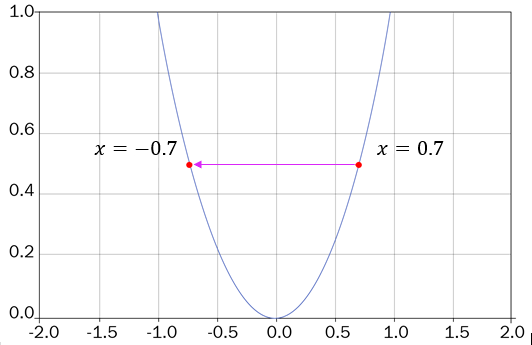

So, to avoid this we introduce a new parameter called learning rate $\alpha$. It helps us to slow
down our gradient steps so that we won't miss out the minimal point. We multiply our
gradients by the learning rate and update the $x$ value as,

$$x=x-\alpha \frac{d y}{d x}$$


Let us say $\alpha = 0.15$ then,

$$x=0.7-(0.15 * 1.4)$$

$$x=0.49$$

As shown in the below figure, after multiplying the gradients with learning rate, with the
updated x value, we descended from the initial position x=0.7 to x =0.49.

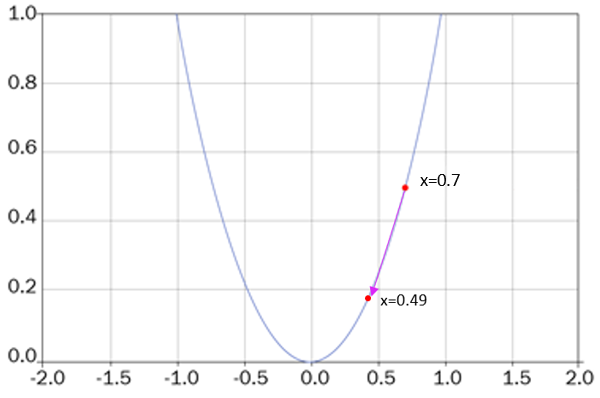

But still, this is not our optimal minimum value. We need to go further down until we
reach the minimum value. i.e x= 0. So for some number n of iterations, we have to repeat
the same process until we reach the minimal point. That is,

$$x=x-\alpha \cdot \frac{d y}{d x}$$


Okay, why is there minus in the above equation? That is why are subtracting x from the $\alpha \cdot \frac{d y}{d x}$ Why can't we add them and have our equation as $x=x+\alpha \cdot \frac{d y}{d x}$?


Because we are finding the minimum of a function so we need to go downwards. If we add
x with $\alpha . \frac{d y}{d x}$, then we go upwards on every iteration and we cannot find the minimum
value as shown in the following figure:

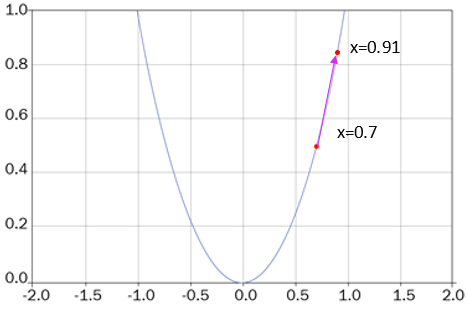

Thus, on every iteration, we compute gradients of y with respect to x i.e $\frac{d y}{d x}$ multiply the
gradients with learning rate i.e $\alpha . \frac{d y}{d x}$ and subtract it from x value and get the new updated x value:

$$x=x-\alpha \cdot \frac{d y}{d x}$$

By repeating this step on every iteration, we go downwards on our cost function and reach
the minimum point. As shown in the below figure, from initial position 0.7 we reached 0.49
and then from there we reached 0.2 then after several iterations we reached the minimum
point 0.

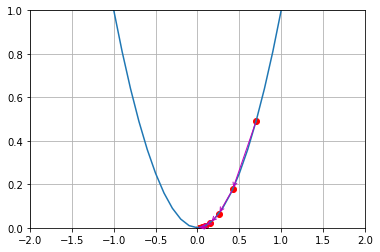


We say we attained convergence when we reach the minimum of the function. But the
question is, how do we know that we attained convergence? In our example, $y=x^{2}$,  we
know that the minimum value is 0. So when we reached 0 we said that we found the
minimum value. i.e attained the convergence. But how can we mathematically say that 0 is the minimum value of the function  $y=x^{2}$? 


Let us take a closer look at the below graph which shows how the value of x is getting
changed on every iteration. As you may notice, the value of x is 0.009 in the 5th iteration
and it is 0.008 in 6th iteration and it is 0.007 in 7th iteration. If you see there is no huge
difference between all these iterations 5, 6 and 7. When there a is very less change in x value
over iterations, then we can conclude that we attained convergence.

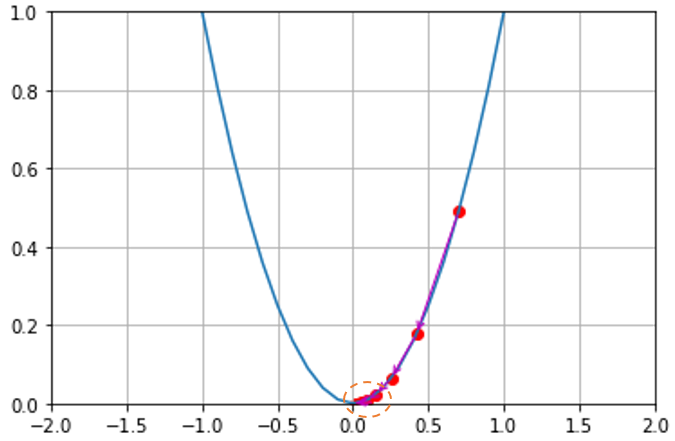


Okay, but what is the use of all this? Why are we trying to find the minimum of a
function? When training a model our goal is to minimize the loss function of the
model. Thus, with gradient descent, we can find the minimum of the cost function. Finding
the minimum of the cost function gives us an optimal parameter of the model with which
we can obtain the minimal loss. In general, we denote the parameters of the model  $\theta$. The
below equation is called the parameter update rule or weight update rule. 

$$ \theta=\theta-\alpha \cdot \nabla_{\theta} J(\theta)$$


Where, 

* $ \theta $ is the parameter of the model
* $\alpha$ is the learning rate
* $\nabla_{\theta} J(\theta)$ is the gradients of loss function $J$ with respect to parameter $\theta$